# CIRRUS++: Empirical Rule Induction for Domain-Aware Time-Series Preprocessing

**Goal.** Derive transparent preprocessing recommendations from controlled experiments instead of validating hand-written thresholds against themselves.

The notebook combines:

1. universal time-series profiling,
2. synthetic signal families from six domains,
3. controlled corruption with known ground truth,
4. domain-specific evaluation objectives,
5. stage-level benchmarking,
6. interpretable rule induction and leave-one-domain-out validation.

The synthetic data are test fixtures. They do not replace real datasets. The intended final evidence is a combination of synthetic clean-reference experiments, heterogeneous real datasets, and sensitivity analyses.

## Scientific guardrails

- **Kurtosis is descriptive, not a corruption label.** High excess kurtosis may represent measurement spikes, genuine peaks, regime mixtures, or heavy tails.
- **Missing rate alone is insufficient.** Gap duration, burstiness, autocorrelation, and cross-channel information are explicit profile variables.
- **Domain weights are declared objectives.** They must be reported and varied; they are not presented as discovered facts.
- **Scaling is task-aware.** Affine scalers do not intrinsically differ in skewness or kurtosis preservation. Raw-signal quality is evaluated after inverse scaling, and normalization should later be validated against downstream model families.
- **No forced winner.** Near-ties are retained. CIRRUS++ may legitimately report that no method is stable enough for an automatic recommendation.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from cirruspp_benchmark.generators import GENERATORS, generate_domain_series
from cirruspp_benchmark.corruptions import inject_corruption
from cirruspp_benchmark.profiling import profile_dataframe
from cirruspp_benchmark.preprocessing import PipelineSpec, apply_pipeline
from cirruspp_benchmark.evaluation import evaluate_reconstruction, domain_weighted_loss
from cirruspp_benchmark.domain_profiles import load_domain_profiles, validate_profiles
from cirruspp_benchmark.benchmark import (
    estimate_method_runs, load_config, run_stage_benchmark, summarize_winners
)
from cirruspp_benchmark.rule_induction import (
    fit_interpretable_rules, grouped_cv_accuracy,
    bootstrap_method_support, export_rule_bundle,
)

DOMAIN_PROFILES = load_domain_profiles(ROOT / "configs" / "domains.yaml")
validate_profiles(DOMAIN_PROFILES)
list(DOMAIN_PROFILES)
from cirruspp_benchmark.sensitivity import recommendation_stability

from cirruspp_benchmark.progress import NotebookProgress
from cirruspp_benchmark.real_data import RealDatasetSpec, load_real_dataset, make_eye_tracking_spec


## 1. Inspect the six synthetic signal families

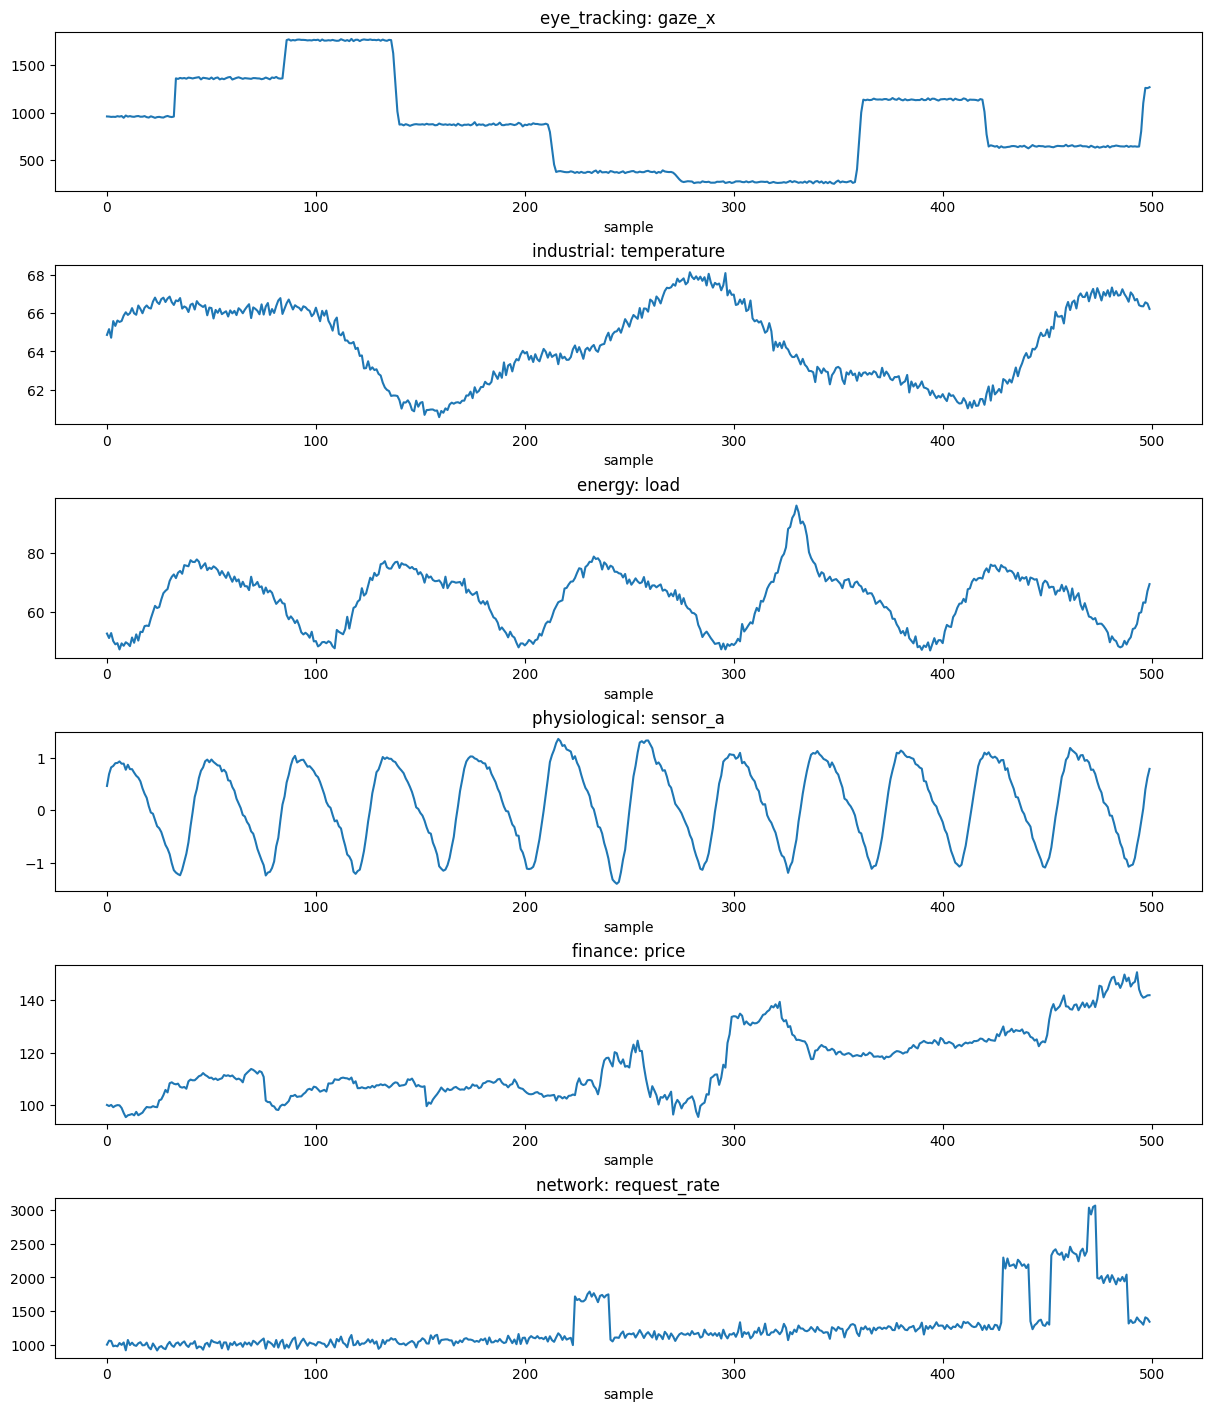

In [2]:
examples = {d: generate_domain_series(d, n=900, seed=11) for d in GENERATORS}
fig, axes = plt.subplots(len(examples), 1, figsize=(12, 14), constrained_layout=True)
for ax, (domain, series) in zip(axes, examples.items()):
    cols = [c for c in series.clean.columns if c != "timestamp"]
    ax.plot(series.clean.index[:500], series.clean[cols[0]].iloc[:500])
    ax.set_title(f"{domain}: {cols[0]}")
    ax.set_xlabel("sample")
plt.show()

The families deliberately contain genuine events: eye-movement transitions, operating-state changes, demand peaks, activity bouts, financial jumps, and network incidents. Those events are marked separately so that a pipeline is penalized when it “cleans” real behavior away.

## 2. Controlled degradation and exact masks

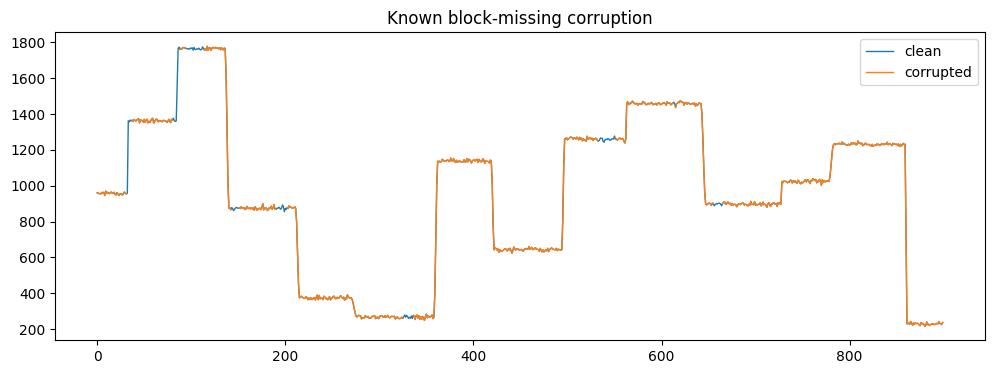

Affected fraction: 0.1


In [3]:
series = examples["eye_tracking"]
corrupted = inject_corruption(series.clean, "block_missing", severity=0.10, seed=17)
feature = "gaze_x"

plt.figure(figsize=(12, 4))
plt.plot(series.clean.index, series.clean[feature], label="clean", linewidth=1)
plt.plot(corrupted.data.index, corrupted.data[feature], label="corrupted", linewidth=1)
plt.title("Known block-missing corruption")
plt.legend()
plt.show()

print("Affected fraction:", corrupted.combined_mask[feature].mean())

## 3. Universal profiling, including excess kurtosis

In [4]:
feature_profiles = profile_dataframe(corrupted.data, fs=series.metadata["sampling_rate_hz"], aggregate=False)
feature_profiles.T

,0,1,2,3
feature,gaze_x,gaze_y,pupil_left,pupil_right
n,900,900,900,900
missing_rate,0.1,0.1,0.1,0.094444
longest_missing_run_seconds,0.166667,0.166667,0.275,0.183333
missing_run_p95_seconds,0.16,0.164167,0.265,0.165833
missing_burstiness,0.175556,0.184444,0.278333,0.201291
outlier_iqr_rate,0.0,0.0,0.0,0.0
outlier_mad_rate,0.0,0.0,0.0,0.0
skewness,-0.229012,-0.00703,-0.139527,-0.157676
kurtosis_excess,-0.89034,-1.689562,-1.493021,-1.41969


The rule model will receive measured signal properties, not the hidden corruption label in the final deployment setting. During benchmark analysis, the known corruption type is retained for stratified diagnostics and failure analysis.

## 4. Compare candidate methods against clean ground truth

In [5]:
methods = ["mean", "median", "locf", "linear", "knn", "mice"]
rows = []
for method in methods:
    spec = PipelineSpec(imputation=method)
    processed, aux = apply_pipeline(corrupted.data, spec, fs=series.metadata["sampling_rate_hz"], seed=11)
    metrics = evaluate_reconstruction(
        series.clean, corrupted.data, processed, corrupted.combined_mask,
        series.event_mask, series.metadata["sampling_rate_hz"], None
    )
    loss = domain_weighted_loss(metrics, DOMAIN_PROFILES["eye_tracking"]["loss_weights"])
    rows.append({"method": method, "weighted_loss": loss, **metrics})
comparison = pd.DataFrame(rows).sort_values("weighted_loss")
comparison

,method,weighted_loss,reconstruction,clean_harm,dynamics,distribution,frequency,event,det_precision,det_recall,det_f1,detection,retention,overall_unweighted
3,linear,0.105574,0.209550,0.0,0.255873,0.009486,0.003825,0.048985,NaN,NaN,NaN,0.0,0.0,0.065965
2,locf,0.133857,0.255066,0.0,0.332748,0.010008,0.003799,0.068018,NaN,NaN,NaN,0.0,0.0,0.083705
5,mice,0.187452,0.420699,0.0,0.405560,0.043169,0.022513,0.061382,NaN,NaN,NaN,0.0,0.0,0.119165
4,knn,0.203338,0.427732,0.0,0.489388,0.033107,0.028053,0.048720,NaN,NaN,NaN,0.0,0.0,0.128375
0,mean,0.217086,0.490394,0.0,0.457319,0.062013,0.053037,0.067481,NaN,NaN,NaN,0.0,0.0,0.141281
1,median,0.219992,0.499598,0.0,0.458145,0.069357,0.054906,0.067714,NaN,NaN,NaN,0.0,0.0,0.143715


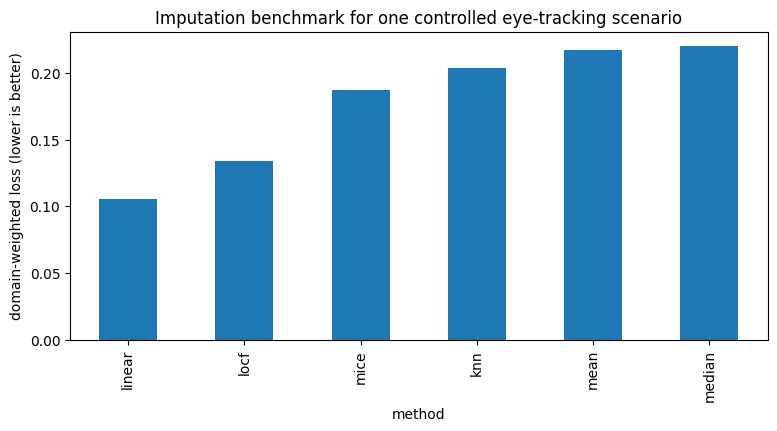

In [6]:
comparison.plot.bar(x="method", y="weighted_loss", figsize=(9, 4), legend=False)
plt.ylabel("domain-weighted loss (lower is better)")
plt.title("Imputation benchmark for one controlled eye-tracking scenario")
plt.show()

## 5. Domain weights change the objective, not the raw measurements

In [7]:
weight_table = pd.DataFrame({d: p["loss_weights"] for d, p in DOMAIN_PROFILES.items()}).T
weight_table

,reconstruction,clean_harm,dynamics,distribution,frequency,event,detection,retention
eye_tracking,0.22,0.15,0.2,0.08,0.05,0.15,0.10,0.05
industrial,0.15,0.10,0.1,0.05,0.10,0.20,0.20,0.10
energy,0.15,0.15,0.1,0.05,0.25,0.20,0.05,0.05
physiological,0.15,0.15,0.2,0.05,0.25,0.15,0.03,0.02
finance,0.05,0.25,0.1,0.20,0.00,0.30,0.05,0.05
network,0.10,0.15,0.1,0.05,0.05,0.25,0.20,0.10


For publication, run a sensitivity analysis: perturb each weight vector inside a plausible simplex neighborhood and report recommendation stability. A recommendation that changes under tiny weight perturbations should be displayed as uncertain or tied.

## 6. Weight sensitivity

A domain profile is defensible only if its recommendations are not arbitrarily determined by tiny weight changes. After the benchmark has been run, the following analysis perturbs the declared weights and recomputes method winners.

In [8]:
# This cell is evaluated after the quick benchmark below.
# The executable sensitivity calculation appears in Section 8, once outputs exist.

### Live progress and resumability

Before execution, the benchmark computes the exact number of candidate-method evaluations. During a run it reports the overall percentage, completed and total runs, elapsed time, estimated remaining time, and the currently evaluated domain/method. Partial CSV checkpoints are written periodically so a long publication run does not lose all results after an interruption.

## 7. Run the reproducible quick benchmark

In [9]:
RUN_QUICK_BENCHMARK = True
quick_output = ROOT / "results" / "notebook_quick"

if RUN_QUICK_BENCHMARK:
    config = load_config(ROOT / "configs" / "experiments_quick.yaml")
    print("Planned candidate-method runs:", estimate_method_runs(config))
    outputs = run_stage_benchmark(
        config,
        ROOT / "configs" / "domains.yaml",
        quick_output,
        progress_callback=NotebookProgress(),
        checkpoint_every=50,
    )
    winners = {}
    for stage, df in outputs.items():
        winners[stage] = summarize_winners(df, tolerance=0.02)
        winners[stage].to_csv(quick_output / f"{stage}_winners.csv", index=False)
        print(stage, len(df), "method runs ->", len(winners[stage]), "scenario winners")
else:
    outputs = {
        stage: pd.read_csv(quick_output / f"{stage}_benchmark.csv")
        for stage in ["imputation", "outlier", "smoothing"]
    }
    winners = {
        stage: pd.read_csv(quick_output / f"{stage}_winners.csv")
        for stage in outputs
    }


Planned candidate-method runs: 132


**CIRRUS++ benchmark:** `████████████████████████████████████` **100.00%**  (132/132)  \nElapsed: 0:00:04 · ETA: 0:00:00  \nCurrent: `network · high_frequency_noise · smoothing · butterworth`

/opt/pyvenv/lib/python3.13/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


imputation 72 method runs -> 12 scenario winners
outlier 36 method runs -> 6 scenario winners
smoothing 24 method runs -> 6 scenario winners


## 8. Inspect cross-domain winner patterns, near-ties, and weight stability

In [10]:
for stage, win in winners.items():
    print("\n", stage.upper())
    display(pd.crosstab(win["domain"], win["winner"], normalize="index").round(2))
    print("Near-tie fraction:", (win["near_tie_count"] > 1).mean())


 IMPUTATION


winner,linear,locf,mean
domain,,,
energy,1.0,0.0,0.0
eye_tracking,1.0,0.0,0.0
finance,1.0,0.0,0.0
industrial,1.0,0.0,0.0
network,0.0,0.5,0.5
physiological,1.0,0.0,0.0


Near-tie fraction: 0.6666666666666666

 OUTLIER


winner,iqr,winsorize,zscore
domain,,,
energy,1.0,0.0,0.0
eye_tracking,0.0,0.0,1.0
finance,0.0,1.0,0.0
industrial,1.0,0.0,0.0
network,0.0,1.0,0.0
physiological,0.0,0.0,1.0


Near-tie fraction: 0.3333333333333333

 SMOOTHING


winner,moving_median,none
domain,,
energy,1.0,0.0
eye_tracking,1.0,0.0
finance,0.0,1.0
industrial,0.0,1.0
network,0.0,1.0
physiological,1.0,0.0


Near-tie fraction: 0.8333333333333334


In [11]:
stage = "imputation"
weight_stability = []
for domain in DOMAIN_PROFILES:
    subset = outputs[stage][outputs[stage]["domain"] == domain]
    if subset.empty:
        continue
    stab = recommendation_stability(
        subset, DOMAIN_PROFILES[domain]["loss_weights"],
        n_draws=250, concentration=120, seed=42
    )
    stab["domain"] = domain
    weight_stability.append(stab)
weight_stability = pd.concat(weight_stability, ignore_index=True)
(weight_stability.groupby(["domain", "method"])["support"].mean()
 .sort_values(ascending=False).groupby(level=0).head(3).to_frame())

support
domain        method         
energy        linear      1.0
eye_tracking  linear      1.0
finance       linear      1.0
industrial    linear      1.0
network       linear      1.0
              mice        1.0
physiological linear      1.0

## 9. Induce a small, auditable rule model

In [12]:
stage = "imputation"
rule_result = fit_interpretable_rules(
    winners[stage], max_depth=4, min_samples_leaf=3, holdout_domain="finance"
)
print(rule_result["tree_text"])
print("Leave-finance-out accuracy:", rule_result.get("holdout_accuracy"))

|--- num__profile_lag1_autocorr <= 0.9698
|   |--- class: locf
|--- num__profile_lag1_autocorr >  0.9698
|   |--- class: linear

Leave-finance-out accuracy: 0.0


A shallow tree is intentionally restrictive. If its accuracy is low, the answer is not automatically “use a bigger black box.” It may mean that the available profile variables are insufficient or that no stable universal rule exists.

## 10. Grouped validation and bootstrap support

In [13]:
cv = grouped_cv_accuracy(winners[stage], max_depth=4, min_samples_leaf=3)
cv

,fold,accuracy,n_test
0,0,0.666667,3
1,1,0.666667,3
2,2,0.500000,2
3,3,0.500000,2
4,4,1.000000,2


In [14]:
support = bootstrap_method_support(winners[stage], n_boot=100, seed=42)
summary_support = support.groupby(["domain", "method"])["support"].agg(["mean", "std"]).reset_index()
summary_support.sort_values(["domain", "mean"], ascending=[True, False]).head(20)

,domain,method,mean,std
0,energy,linear,1.000000,0.000000
1,eye_tracking,linear,1.000000,0.000000
2,finance,linear,1.000000,0.000000
3,industrial,linear,1.000000,0.000000
5,network,mean,0.669444,0.252620
4,network,locf,0.668810,0.270488
6,physiological,linear,1.000000,0.000000


## 11. Export rules for CIRRUS++

In [15]:
artifact_dir = ROOT / "artifacts" / "notebook_quick"
export_rule_bundle(
    rule_result, artifact_dir, stage,
    metadata={"benchmark": "quick smoke test", "warning": "not publication evidence"}
)
print("Exported to", artifact_dir)

Exported to /mnt/data/CIRRUSpp_empirical_benchmark_v2/artifacts/notebook_quick


## 12. Real-data adapters and publication run

The benchmark can already continue without external files. Synthetic domains are sufficient for developing and testing the rule-induction machinery. Real data are needed later for three purposes: validating column mappings, checking whether the synthetic signal families cover realistic profiles, and producing the final paper evidence.

The generic adapter accepts CSV/TSV files, an explicit sampling rate, optional column mappings, and participant/file-level grouping through the source-file metadata. For eye-tracking data it recognizes common gaze and pupil column aliases automatically.

```python
spec = make_eye_tracking_spec(
    name="autism",
    path=ROOT / "data" / "autism",
    sampling_rate_hz=60,
    file_glob="*.csv",
    max_files=5,  # use None for the final run
)
real_series = load_real_dataset(spec)
real_series[0].metadata
```

For a non-eye-tracking dataset:

```python
spec = RealDatasetSpec(
    name="industrial_example",
    domain="industrial",
    path=ROOT / "data" / "industrial",
    sampling_rate_hz=10,
    file_glob="*.csv",
    timestamp_column="time",
    feature_columns=["temperature", "pressure", "vibration"],
)
real_series = load_real_dataset(spec)
```

Before the publication run:

1. provide at least 3–5 representative files per real dataset to validate the loaders;
2. freeze exact software versions and random seeds;
3. define participant/file-level groups to prevent leakage;
4. decide the domain-weight sensitivity range;
5. pre-register primary metrics and tie tolerance;
6. keep one domain and one real dataset as untouched external hold-outs.

The command-line runner now displays percentage, completed runs, elapsed time, ETA, current domain, corruption, stage, and method. It also writes partial checkpoints:

```bash
python scripts/run_benchmark.py --config configs/experiments_full.yaml --output results/publication
python scripts/induce_rules.py --results results/publication --artifacts artifacts/publication --holdout-domain finance
```


## 13. Intended CIRRUS++ user-facing explanation

For each recommendation, the application should show:

- triggering profile values,
- domain objective and weights,
- recommended and second-best methods,
- support across bootstrap samples,
- expected regret against the benchmark oracle,
- applicable signal families and severity range,
- a warning when no stable recommendation exists.

The current prototype's generic “confidence” should be replaced by explicitly named empirical support or stability.